# IBM Quantum Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 2: Make the Quantum Coin Biased

**Goal:** A Hadamard gate gives a fair quantum coin (50% `0`, 50% `1`). Here we change the gates so that the outcomes are **not** equally likely, run each circuit for **100 shots**, and show the results in histograms.

**Design constraints satisfied:** exactly 1 qubit, starts in |0>, measurement included, **at most 4 gates before measurement** (every circuit below uses 1 to 4), built and executed with Qiskit, 100 shots per experiment.

## Step 0: Setup

In [1]:
# Install dependencies (skip if already installed)
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
from math import pi, sqrt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
backend = AerSimulator()


def run_circuit(qc, shots=SHOTS):
    """Execute a measured circuit and always return counts for both '0' and '1'."""
    compiled = transpile(qc, backend)
    raw = backend.run(compiled, shots=shots).result().get_counts()
    return {'0': raw.get('0', 0), '1': raw.get('1', 0)}


def exact_probabilities(qc_without_measurement):
    """Exact theoretical P(0), P(1) from the state vector (used as the prediction check)."""
    p = Statevector(qc_without_measurement).probabilities()
    return {'0': float(p[0]), '1': float(p[1])}


def within_noise(count, p, shots=SHOTS, k=4):
    """True if a count is within k standard deviations of the expected value shots*p."""
    sd = sqrt(shots * p * (1 - p))
    return abs(count - shots * p) <= k * sd + 1

## Idea: how to bias the coin

The **RY rotation gate** turns |0> into a state whose amplitudes depend on the angle theta:

RY(theta)|0> = cos(theta/2)|0> + sin(theta/2)|1>

The measurement probabilities are the squared amplitudes (Born rule):

- **P(0) = cos^2(theta/2)**
- **P(1) = sin^2(theta/2)**

| theta | P(0) | P(1) | Behaviour |
|---|---|---|---|
| 0 | 100% | 0% | no rotation, always 0 |
| pi/6 | 93.3% | 6.7% | strongly biased to 0 |
| pi/3 | 75% | 25% | biased to 0 |
| pi/2 | 50% | 50% | fair coin (same as H) |
| 2pi/3 | 25% | 75% | biased to 1 |
| 5pi/6 | 6.7% | 93.3% | strongly biased to 1 |
| pi | 0% | 100% | full flip (same as X) |

## Part 1: Main biased circuit

**Circuit:** |0> -> RY(pi/3) -> measure (1 gate before measurement).

### Prediction (made before running)

- **Which outcome is more frequent?** `0`.
- **Approximate percentages:** P(0) = cos^2(pi/6) = **75%** and P(1) = sin^2(pi/6) = **25%**, so about 75 zeros and 25 ones in 100 shots.
- **What if the gates change?** A different rotation angle (or different gates) changes the amplitudes and therefore the percentages (see Part 2).

In [4]:
theta_main = pi / 3

# Circuit without measurement (only to compute the exact prediction)
main_core = QuantumCircuit(1)
main_core.ry(theta_main, 0)

# The circuit that is executed: 1 qubit, 1 classical bit, measurement included
qc_main = QuantumCircuit(1, 1, name='Biased coin')
qc_main.ry(theta_main, 0)
qc_main.measure(0, 0)
print(qc_main.draw('text'))

pred_main = exact_probabilities(main_core)
print(f"\nPredicted probabilities: P(0) = {pred_main['0']:.3f}, P(1) = {pred_main['1']:.3f}")
print(f"Predicted counts for {SHOTS} shots: about {pred_main['0']*SHOTS:.0f} zeros and {pred_main['1']*SHOTS:.0f} ones")

     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 

Predicted probabilities: P(0) = 0.750, P(1) = 0.250
Predicted counts for 100 shots: about 75 zeros and 25 ones


Measurement results (100 shots): {'0': 76, '1': 24}
Observed: 76% zeros, 24% ones


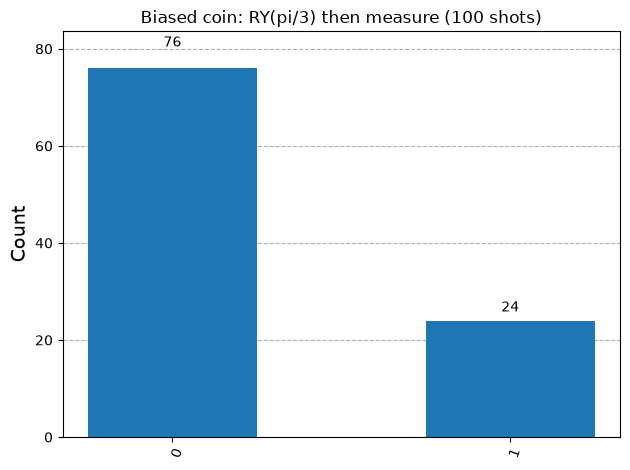

In [5]:
counts_main = run_circuit(qc_main)
print('Measurement results (100 shots):', counts_main)
print(f"Observed: {counts_main['0']}% zeros, {counts_main['1']}% ones")
display(plot_histogram(counts_main, title='Biased coin: RY(pi/3) then measure (100 shots)'))

## Part 2: Different degrees of bias

Changing only the angle of the RY gate gives coins with different bias. Every circuit has 1 gate before measurement.

In [6]:
angles = [
    ('RY(pi/6)',  pi / 6),
    ('RY(pi/3)',  pi / 3),
    ('RY(pi/2)',  pi / 2),
    ('RY(2pi/3)', 2 * pi / 3),
    ('RY(5pi/6)', 5 * pi / 6),
]

sweep_counts, sweep_preds = {}, {}
for label, th in angles:
    core = QuantumCircuit(1)
    core.ry(th, 0)
    qc = QuantumCircuit(1, 1)
    qc.ry(th, 0)
    qc.measure(0, 0)
    sweep_preds[label] = exact_probabilities(core)
    sweep_counts[label] = run_circuit(qc)

print(f"{'Circuit':<11}{'Predicted P(0)/P(1)':<22}{'Actual 0 / 1 (100 shots)':<26}Match?")
print('-' * 66)
for label, _ in angles:
    p0, p1 = sweep_preds[label]['0'], sweep_preds[label]['1']
    c0, c1 = sweep_counts[label]['0'], sweep_counts[label]['1']
    ok = within_noise(c0, p0) and within_noise(c1, p1)
    print(f"{label:<11}{f'{p0:.3f} / {p1:.3f}':<22}{f'{c0} / {c1}':<26}{'YES' if ok else 'NO'}")

Circuit    Predicted P(0)/P(1)   Actual 0 / 1 (100 shots)  Match?
------------------------------------------------------------------
RY(pi/6)   0.933 / 0.067         92 / 8                    YES
RY(pi/3)   0.750 / 0.250         77 / 23                   YES
RY(pi/2)   0.500 / 0.500         47 / 53                   YES
RY(2pi/3)  0.250 / 0.750         26 / 74                   YES
RY(5pi/6)  0.067 / 0.933         5 / 95                    YES


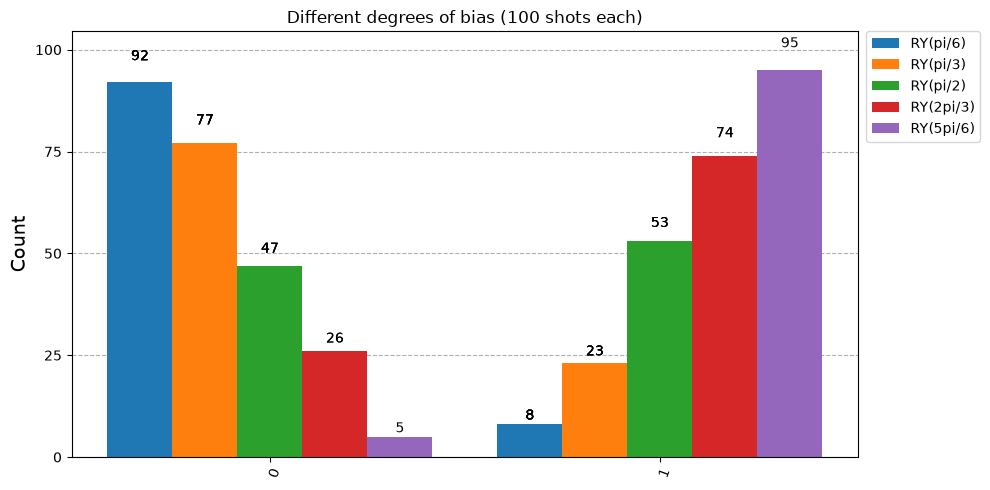

In [7]:
labels = [l for l, _ in angles]
display(plot_histogram(
    [sweep_counts[l] for l in labels],
    legend=labels,
    title='Different degrees of bias (100 shots each)',
    figsize=(10, 5),
))

## Part 3: Bonus Challenge (two different circuits)

- **Circuit Z (0 occurs more often):** |0> -> RY(pi/3) -> measure. Prediction: P(0) = 75%, P(1) = 25%.
- **Circuit O (1 occurs more often):** |0> -> RY(2pi/3) -> measure. Prediction: P(0) = 25%, P(1) = 75%.

Circuit O is the mirror image of Circuit Z: it uses the supplementary angle, which swaps the two probabilities.

In [8]:
# Circuit Z: 0 more frequent
core_z = QuantumCircuit(1); core_z.ry(pi / 3, 0)
qc_z = QuantumCircuit(1, 1, name='Circuit Z'); qc_z.ry(pi / 3, 0); qc_z.measure(0, 0)

# Circuit O: 1 more frequent
core_o = QuantumCircuit(1); core_o.ry(2 * pi / 3, 0)
qc_o = QuantumCircuit(1, 1, name='Circuit O'); qc_o.ry(2 * pi / 3, 0); qc_o.measure(0, 0)

print('Circuit Z (0 more frequent)'); print(qc_z.draw('text'))
print('\nCircuit O (1 more frequent)'); print(qc_o.draw('text'))

pred_z, pred_o = exact_probabilities(core_z), exact_probabilities(core_o)
counts_z, counts_o = run_circuit(qc_z), run_circuit(qc_o)

print(f"\nCircuit Z predicted P(0)/P(1) = {pred_z['0']:.2f}/{pred_z['1']:.2f} | actual counts: {counts_z}")
print(f"Circuit O predicted P(0)/P(1) = {pred_o['0']:.2f}/{pred_o['1']:.2f} | actual counts: {counts_o}")

Circuit Z (0 more frequent)
     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 

Circuit O (1 more frequent)
     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 

Circuit Z predicted P(0)/P(1) = 0.75/0.25 | actual counts: {'0': 81, '1': 19}
Circuit O predicted P(0)/P(1) = 0.25/0.75 | actual counts: {'0': 25, '1': 75}


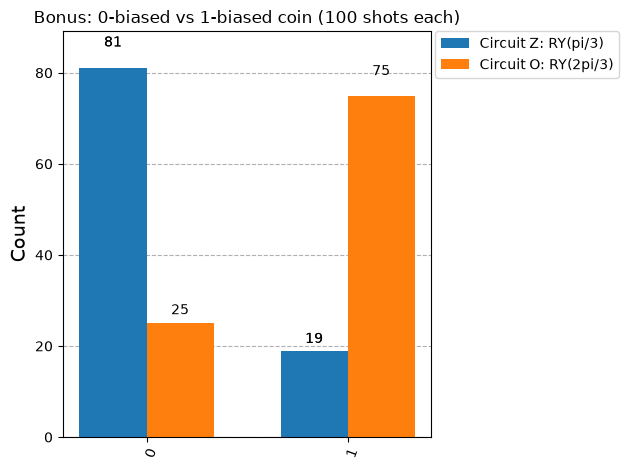

In [9]:
display(plot_histogram(
    [counts_z, counts_o],
    legend=['Circuit Z: RY(pi/3)', 'Circuit O: RY(2pi/3)'],
    title='Bonus: 0-biased vs 1-biased coin (100 shots each)',
))

### Alternative bias circuits using multiple gates (still at most 4 gates)

The sequence **H, T, H** gives P(0) = cos^2(pi/8) = 85.4% and P(1) = 14.6%. Starting with an **X** gate (X, H, T, H) flips the bias to P(1) = 85.4%. The T gate adds a phase of pi/4 to |1>, and the second H turns that phase difference into a probability difference.

H, T, H
     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 

X, H, T, H
     ┌───┐┌───┐┌───┐┌───┐┌─┐
  q: ┤ X ├┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└───┘└╥┘
c: 1/═════════════════════╩═
                          0 

H,T,H    predicted P(0)/P(1) = 0.854/0.146 | actual counts: {'0': 87, '1': 13}
X,H,T,H  predicted P(0)/P(1) = 0.146/0.854 | actual counts: {'0': 17, '1': 83}


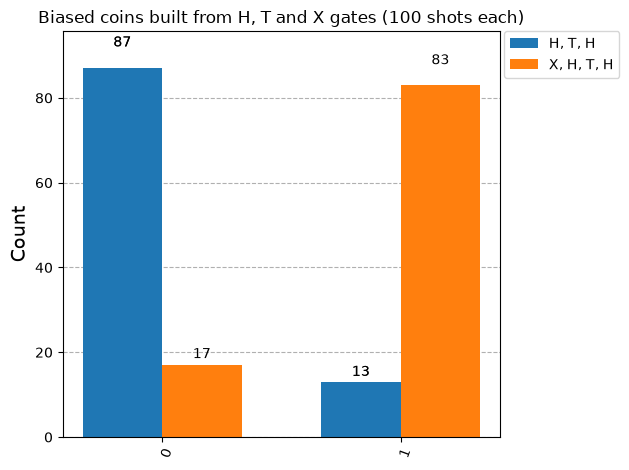

In [10]:
# H, T, H (3 gates): 0 more frequent
core_hth = QuantumCircuit(1); core_hth.h(0); core_hth.t(0); core_hth.h(0)
qc_hth = QuantumCircuit(1, 1); qc_hth.h(0); qc_hth.t(0); qc_hth.h(0); qc_hth.measure(0, 0)

# X, H, T, H (4 gates): 1 more frequent
core_xhth = QuantumCircuit(1); core_xhth.x(0); core_xhth.h(0); core_xhth.t(0); core_xhth.h(0)
qc_xhth = QuantumCircuit(1, 1); qc_xhth.x(0); qc_xhth.h(0); qc_xhth.t(0); qc_xhth.h(0); qc_xhth.measure(0, 0)

print('H, T, H'); print(qc_hth.draw('text'))
print('\nX, H, T, H'); print(qc_xhth.draw('text'))

pred_hth, pred_xhth = exact_probabilities(core_hth), exact_probabilities(core_xhth)
counts_hth, counts_xhth = run_circuit(qc_hth), run_circuit(qc_xhth)
print(f"\nH,T,H    predicted P(0)/P(1) = {pred_hth['0']:.3f}/{pred_hth['1']:.3f} | actual counts: {counts_hth}")
print(f"X,H,T,H  predicted P(0)/P(1) = {pred_xhth['0']:.3f}/{pred_xhth['1']:.3f} | actual counts: {counts_xhth}")

display(plot_histogram(
    [counts_hth, counts_xhth],
    legend=['H, T, H', 'X, H, T, H'],
    title='Biased coins built from H, T and X gates (100 shots each)',
))

## Summary: how the gates changed the measurement distribution

- **Fair coin (H gate):** gives equal amplitudes, so P(0) = P(1) = 50%.
- **RY(theta):** sets the amplitudes to cos(theta/2) and sin(theta/2). A small angle keeps the qubit near |0>, so `0` dominates; a large angle moves it toward |1>, so `1` dominates. This is why RY(pi/3) gave about 75% zeros and RY(2pi/3) gave about 75% ones.
- **Different degrees of bias:** pi/6 and 5pi/6 give the strongest bias (about 93%), pi/3 and 2pi/3 a moderate bias (75%), and pi/2 returns the fair coin (50%).
- **Multi-gate circuits:** H, T, H gives about 85% zeros; adding X first gives about 85% ones. A phase gate (T) does not change probabilities by itself, but between two Hadamard gates it does.
- **Randomness:** with only 100 shots the counts fluctuate around the predicted values (the standard deviation is about 4 shots for a 75/25 split), so they match the predictions closely but not exactly, and change slightly on each run.

All circuits use exactly 1 qubit, at most 4 gates before measurement, and 100 shots.

## Challenge Question

**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

**Answer:** A qubit's state is a superposition a|0> + b|1>, and measurement gives `0` with probability |a|^2 and `1` with probability |b|^2. Quantum gates are unitary operations that change the amplitudes a and b before measurement, and therefore change these probabilities. A rotation gate such as RY(theta) sets a = cos(theta/2) and b = sin(theta/2), so the angle directly controls the bias: P(0) = cos^2(theta/2) and P(1) = sin^2(theta/2). The X gate swaps the amplitudes of |0> and |1> (turning certain 0 into certain 1), the H gate creates an equal 50/50 superposition, and gates that only add phase (such as T) change the probabilities only when combined with other gates such as H, because the phase then affects interference. By choosing and combining gates, we can tune the measurement probabilities anywhere between always `0` and always `1`, while each individual measurement outcome remains random and only the statistics over many shots follow these probabilities.